ROULETTE THEORETICAL MODEL
P(win) = 0.4864864864864865
P(loss) = 0.5135135135135135
e_R = -0.027027027027026973
Var(X_R) = 0.9992695398100804

ROULETTE MONTE CARLO CHECK
------------------------------------------------------------
Number of trials = 300000
Theoretical e_R = -0.027027027027026973
Simulated e_R = -0.032413333333333336
Difference = -0.005386306306306363
Standard error = 0.0018250749206631495
Difference in standard errors = -2.9512795586217484
Theoretical variance = 0.9992695398100804
Simulated variance = 0.998949375822222
PASS: Roulette simulation agrees with theory.

BLACKJACK THEORETICAL MODEL
P(win) = 0.40882365780313734
P(loss) = 0.48891543790007624
P(push) = 0.10226090429678641
Probability sum = 1.0
e_B = -0.0800917800969389
Var(X_B) = 0.8913244024641173

BLACKJACK MONTE CARLO CHECK
------------------------------------------------------------
Number of trials = 300000
Theoretical e_B = -0.0800917800969389
Simulated e_B = -0.07522666666666666
Difference = 0.0048651134

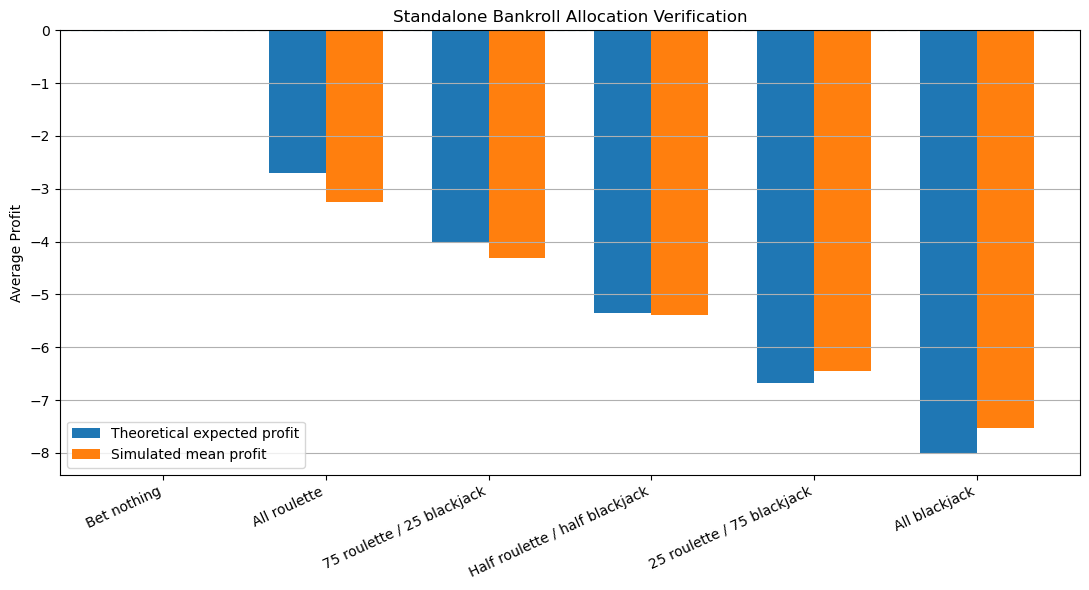

In [2]:
# ============================================================
# PART III: EXPECTED VALUE AND BANKROLL ALLOCATION
# STANDALONE VERIFICATION
#
# This cell does NOT depend on Parts I or II.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import lru_cache


# ============================================================
# SETTINGS
# ============================================================

B = 100.0

NUM_TRIALS = 300_000

ROULETTE_SEED = 42

BLACKJACK_SEED = 43


# ============================================================
# PART A: ROULETTE MODEL
# ============================================================

red_numbers = np.array([
    1, 3, 5, 7, 9,
    12, 14, 16, 18,
    19, 21, 23, 25, 27,
    30, 32, 34, 36
])


p_R_win = 18 / 37

p_R_loss = 19 / 37


# Expected payoff per dollar
e_R = (
    p_R_win
    -
    p_R_loss
)


# Since X_R is always +1 or -1,
# E[X_R^2] = 1

var_R = (
    1
    -
    e_R**2
)


print("=" * 60)

print(
    "ROULETTE THEORETICAL MODEL"
)

print("=" * 60)

print(
    "P(win) =",
    p_R_win
)

print(
    "P(loss) =",
    p_R_loss
)

print(
    "e_R =",
    e_R
)

print(
    "Var(X_R) =",
    var_R
)


# ============================================================
# ROULETTE MONTE CARLO SIMULATION
# ============================================================

rng_R = np.random.default_rng(
    ROULETTE_SEED
)


roulette_spins = rng_R.integers(
    0,
    37,
    size=NUM_TRIALS
)


roulette_is_red = np.isin(
    roulette_spins,
    red_numbers
)


roulette_payoffs = np.where(
    roulette_is_red,
    1.0,
    -1.0
)


sim_e_R = np.mean(
    roulette_payoffs
)


sim_var_R = np.var(
    roulette_payoffs
)


se_R = np.sqrt(
    var_R
    /
    NUM_TRIALS
)


z_R = (
    sim_e_R - e_R
) / se_R


print()

print(
    "ROULETTE MONTE CARLO CHECK"
)

print("-" * 60)

print(
    "Number of trials =",
    NUM_TRIALS
)

print(
    "Theoretical e_R =",
    e_R
)

print(
    "Simulated e_R =",
    sim_e_R
)

print(
    "Difference =",
    sim_e_R - e_R
)

print(
    "Standard error =",
    se_R
)

print(
    "Difference in standard errors =",
    z_R
)

print(
    "Theoretical variance =",
    var_R
)

print(
    "Simulated variance =",
    sim_var_R
)


if abs(z_R) < 4:

    print(
        "PASS: Roulette simulation agrees "
        "with theory."
    )

else:

    print(
        "WARNING: Roulette simulation differs "
        "from theory more than expected."
    )


# ============================================================
# PART B: BLACKJACK MODEL
#
# Rules:
#
# Player hits below 17
# Player stands on 17+
#
# Dealer hits below 17
# Dealer stands on 17+
#
# No splitting
# No doubling
# No surrender
#
# Win  = +1
# Push =  0
# Loss = -1
#
# Natural blackjack has no special 3:2 payout.
# ============================================================


card_values = (
    11,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10
)


initial_counts = (
    4,      # aces
    4,      # twos
    4,
    4,
    4,
    4,
    4,
    4,
    4,      # nines
    16      # 10, J, Q, K
)


# ============================================================
# Add one card while handling aces correctly
# ============================================================

def add_card(
    total,
    soft_aces,
    card
):

    if card == 11:

        total += 11

        soft_aces += 1

    else:

        total += card


    while (
        total > 21
        and
        soft_aces > 0
    ):

        total -= 10

        soft_aces -= 1


    return (
        total,
        soft_aces
    )


# ============================================================
# Exact recursive dealer calculation
# ============================================================

@lru_cache(None)
def dealer_probabilities(
    counts,
    player_total,
    dealer_total,
    dealer_soft_aces
):

    # Dealer busts
    if dealer_total > 21:

        return (
            1.0,
            0.0,
            0.0
        )


    # Dealer stands on 17 or more
    if dealer_total >= 17:

        if player_total > dealer_total:

            return (
                1.0,
                0.0,
                0.0
            )

        elif player_total < dealer_total:

            return (
                0.0,
                1.0,
                0.0
            )

        else:

            return (
                0.0,
                0.0,
                1.0
            )


    cards_remaining = sum(
        counts
    )


    p_win = 0.0

    p_loss = 0.0

    p_push = 0.0


    for i, count in enumerate(counts):

        if count == 0:

            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        new_total, new_soft = add_card(
            dealer_total,
            dealer_soft_aces,
            card_values[i]
        )


        w, l, p = dealer_probabilities(
            tuple(new_counts),
            player_total,
            new_total,
            new_soft
        )


        p_win += probability * w

        p_loss += probability * l

        p_push += probability * p


    return (
        p_win,
        p_loss,
        p_push
    )


# ============================================================
# Exact recursive player calculation
# ============================================================

@lru_cache(None)
def player_probabilities(
    counts,
    player_total,
    player_soft_aces,
    dealer_total,
    dealer_soft_aces
):

    # Player busts
    if player_total > 21:

        return (
            0.0,
            1.0,
            0.0
        )


    # Player stands on 17+
    if player_total >= 17:

        return dealer_probabilities(
            counts,
            player_total,
            dealer_total,
            dealer_soft_aces
        )


    cards_remaining = sum(
        counts
    )


    p_win = 0.0

    p_loss = 0.0

    p_push = 0.0


    for i, count in enumerate(counts):

        if count == 0:

            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        new_total, new_soft = add_card(
            player_total,
            player_soft_aces,
            card_values[i]
        )


        w, l, p = player_probabilities(
            tuple(new_counts),
            new_total,
            new_soft,
            dealer_total,
            dealer_soft_aces
        )


        p_win += probability * w

        p_loss += probability * l

        p_push += probability * p


    return (
        p_win,
        p_loss,
        p_push
    )


# ============================================================
# Exact initial deal calculation
#
# Deal order:
#
# Player
# Dealer
# Player
# Dealer
# ============================================================

@lru_cache(None)
def initial_deal_probabilities(
    counts,
    step,
    player_total,
    player_soft_aces,
    dealer_total,
    dealer_soft_aces
):

    if step == 4:

        return player_probabilities(
            counts,
            player_total,
            player_soft_aces,
            dealer_total,
            dealer_soft_aces
        )


    cards_remaining = sum(
        counts
    )


    p_win = 0.0

    p_loss = 0.0

    p_push = 0.0


    for i, count in enumerate(counts):

        if count == 0:

            continue


        probability = (
            count
            /
            cards_remaining
        )


        new_counts = list(
            counts
        )

        new_counts[i] -= 1


        card = card_values[i]


        # Player receives first and third cards
        if step in (0, 2):

            new_player_total, new_player_soft = (
                add_card(
                    player_total,
                    player_soft_aces,
                    card
                )
            )


            w, l, p = (
                initial_deal_probabilities(
                    tuple(new_counts),
                    step + 1,
                    new_player_total,
                    new_player_soft,
                    dealer_total,
                    dealer_soft_aces
                )
            )


        # Dealer receives second and fourth cards
        else:

            new_dealer_total, new_dealer_soft = (
                add_card(
                    dealer_total,
                    dealer_soft_aces,
                    card
                )
            )


            w, l, p = (
                initial_deal_probabilities(
                    tuple(new_counts),
                    step + 1,
                    player_total,
                    player_soft_aces,
                    new_dealer_total,
                    new_dealer_soft
                )
            )


        p_win += probability * w

        p_loss += probability * l

        p_push += probability * p


    return (
        p_win,
        p_loss,
        p_push
    )


# ============================================================
# EXACT BLACKJACK RESULTS
# ============================================================

p_B_win, p_B_loss, p_B_push = (
    initial_deal_probabilities(
        initial_counts,
        0,
        0,
        0,
        0,
        0
    )
)


e_B = (
    p_B_win
    -
    p_B_loss
)


E_B_squared = (
    p_B_win
    +
    p_B_loss
)


var_B = (
    E_B_squared
    -
    e_B**2
)


print()

print("=" * 60)

print(
    "BLACKJACK THEORETICAL MODEL"
)

print("=" * 60)

print(
    "P(win) =",
    p_B_win
)

print(
    "P(loss) =",
    p_B_loss
)

print(
    "P(push) =",
    p_B_push
)

print(
    "Probability sum =",
    p_B_win
    +
    p_B_loss
    +
    p_B_push
)

print(
    "e_B =",
    e_B
)

print(
    "Var(X_B) =",
    var_B
)


# ============================================================
# BLACKJACK MONTE CARLO SIMULATION
# ============================================================

deck_template = np.array(

    [11] * 4

    + [2] * 4
    + [3] * 4
    + [4] * 4
    + [5] * 4
    + [6] * 4
    + [7] * 4
    + [8] * 4
    + [9] * 4

    + [10] * 16,

    dtype=np.int8
)


def hand_total(cards):

    total = sum(
        cards
    )


    aces = sum(
        card == 11
        for card in cards
    )


    while (
        total > 21
        and
        aces > 0
    ):

        total -= 10

        aces -= 1


    return total


def play_blackjack_hand(rng):

    deck = deck_template.copy()


    rng.shuffle(
        deck
    )


    player = [
        int(deck[0]),
        int(deck[2])
    ]


    dealer = [
        int(deck[1]),
        int(deck[3])
    ]


    next_card = 4


    # Player hits below 17
    while hand_total(player) < 17:

        player.append(
            int(deck[next_card])
        )

        next_card += 1


    player_value = hand_total(
        player
    )


    # Player bust
    if player_value > 21:

        return -1


    # Dealer hits below 17
    while hand_total(dealer) < 17:

        dealer.append(
            int(deck[next_card])
        )

        next_card += 1


    dealer_value = hand_total(
        dealer
    )


    # Dealer bust
    if dealer_value > 21:

        return 1


    if player_value > dealer_value:

        return 1


    if player_value < dealer_value:

        return -1


    return 0


rng_B = np.random.default_rng(
    BLACKJACK_SEED
)


blackjack_payoffs = np.fromiter(

    (
        play_blackjack_hand(
            rng_B
        )

        for _ in range(
            NUM_TRIALS
        )
    ),

    dtype=np.int8,

    count=NUM_TRIALS
)


sim_e_B = np.mean(
    blackjack_payoffs
)


sim_var_B = np.var(
    blackjack_payoffs
)


se_B = np.sqrt(
    var_B
    /
    NUM_TRIALS
)


z_B = (
    sim_e_B - e_B
) / se_B


print()

print(
    "BLACKJACK MONTE CARLO CHECK"
)

print("-" * 60)

print(
    "Number of trials =",
    NUM_TRIALS
)

print(
    "Theoretical e_B =",
    e_B
)

print(
    "Simulated e_B =",
    sim_e_B
)

print(
    "Difference =",
    sim_e_B - e_B
)

print(
    "Standard error =",
    se_B
)

print(
    "Difference in standard errors =",
    z_B
)

print(
    "Theoretical variance =",
    var_B
)

print(
    "Simulated variance =",
    sim_var_B
)


if abs(z_B) < 4:

    print(
        "PASS: Blackjack simulation agrees "
        "with theory."
    )

else:

    print(
        "WARNING: Blackjack simulation differs "
        "from theory more than expected."
    )


# ============================================================
# PART C: THEORETICAL BANKROLL OPTIMIZATION
# ============================================================

print()

print("=" * 60)

print(
    "BANKROLL OPTIMIZATION"
)

print("=" * 60)

print(
    "Bankroll B =",
    B
)

print(
    "Roulette e_R =",
    e_R
)

print(
    "Blackjack e_B =",
    e_B
)


# Compare the expected return from:
#
# Keep money: 0
# Roulette: e_R
# Blackjack: e_B


best_rate = max(
    0,
    e_R,
    e_B
)


if best_rate == 0:

    optimal_b_R = 0.0

    optimal_b_B = 0.0


elif best_rate == e_R:

    optimal_b_R = B

    optimal_b_B = 0.0


else:

    optimal_b_R = 0.0

    optimal_b_B = B


optimal_expected_profit = (
    optimal_b_R * e_R
    +
    optimal_b_B * e_B
)


print()

print(
    "THEORETICAL OPTIMAL DECISION"
)

print("-" * 60)

print(
    "Optimal roulette bet =",
    optimal_b_R
)

print(
    "Optimal blackjack bet =",
    optimal_b_B
)

print(
    "Money kept =",
    B
    -
    optimal_b_R
    -
    optimal_b_B
)

print(
    "Maximum expected profit =",
    optimal_expected_profit
)


# ============================================================
# PART D: TEST ALL ALLOCATIONS IN $10 INCREMENTS
# ============================================================

allocation_results = []


step = 10.0


for b_R in np.arange(
    0,
    B + step,
    step
):

    for b_B in np.arange(
        0,
        B - b_R + step,
        step
    ):

        if b_R + b_B > B:

            continue


        money_kept = (
            B
            -
            b_R
            -
            b_B
        )


        theoretical_profit = (
            b_R * e_R
            +
            b_B * e_B
        )


        # Since roulette and blackjack
        # are simulated independently,
        #
        # Var(aX+bY)
        # =
        # a^2 Var(X)
        # +
        # b^2 Var(Y)

        theoretical_variance = (
            b_R**2 * var_R
            +
            b_B**2 * var_B
        )


        combined_profit_samples = (

            b_R
            *
            roulette_payoffs

            +

            b_B
            *
            blackjack_payoffs
        )


        simulated_profit = np.mean(
            combined_profit_samples
        )


        if theoretical_variance > 0:

            standard_error = np.sqrt(
                theoretical_variance
                /
                NUM_TRIALS
            )


            z_score = (
                simulated_profit
                -
                theoretical_profit
            ) / standard_error

        else:

            standard_error = 0.0

            z_score = 0.0


        allocation_results.append({

            "Roulette_Bet":
                b_R,

            "Blackjack_Bet":
                b_B,

            "Money_Kept":
                money_kept,

            "Theoretical_Profit":
                theoretical_profit,

            "Simulated_Profit":
                simulated_profit,

            "Standard_Error":
                standard_error,

            "Z_Score":
                z_score

        })


allocation_df = pd.DataFrame(
    allocation_results
)


# ============================================================
# Find theoretical best allocation
# ============================================================

best_theory_index = allocation_df[
    "Theoretical_Profit"
].idxmax()


best_theory = allocation_df.loc[
    best_theory_index
]


# ============================================================
# Find simulated best allocation
# ============================================================

best_sim_index = allocation_df[
    "Simulated_Profit"
].idxmax()


best_sim = allocation_df.loc[
    best_sim_index
]


print()

print(
    "GRID SEARCH: THEORETICAL BEST"
)

print("-" * 60)

print(
    best_theory.to_string()
)


print()

print(
    "GRID SEARCH: SIMULATED BEST"
)

print("-" * 60)

print(
    best_sim.to_string()
)


# ============================================================
# PART E: IMPORTANT STRATEGIES
# ============================================================

important_strategies = [

    (
        "Bet nothing",
        0.0,
        0.0
    ),

    (
        "All roulette",
        B,
        0.0
    ),

    (
        "75 roulette / 25 blackjack",
        0.75 * B,
        0.25 * B
    ),

    (
        "Half roulette / half blackjack",
        0.50 * B,
        0.50 * B
    ),

    (
        "25 roulette / 75 blackjack",
        0.25 * B,
        0.75 * B
    ),

    (
        "All blackjack",
        0.0,
        B
    )
]


strategy_results = []


for (
    strategy_name,
    b_R,
    b_B
) in important_strategies:


    theoretical_profit = (
        b_R * e_R
        +
        b_B * e_B
    )


    combined_profit = (

        b_R
        *
        roulette_payoffs

        +

        b_B
        *
        blackjack_payoffs
    )


    simulated_profit = np.mean(
        combined_profit
    )


    theoretical_variance = (
        b_R**2 * var_R
        +
        b_B**2 * var_B
    )


    if theoretical_variance > 0:

        standard_error = np.sqrt(
            theoretical_variance
            /
            NUM_TRIALS
        )


        z_score = (
            simulated_profit
            -
            theoretical_profit
        ) / standard_error


    else:

        standard_error = 0.0

        z_score = 0.0


    strategy_results.append({

        "Strategy":
            strategy_name,

        "b_R":
            b_R,

        "b_B":
            b_B,

        "Money_Kept":
            B - b_R - b_B,

        "Theoretical_Profit":
            theoretical_profit,

        "Simulated_Profit":
            simulated_profit,

        "Z_Score":
            z_score

    })


strategy_df = pd.DataFrame(
    strategy_results
)


print()

print(
    "IMPORTANT STRATEGY COMPARISON"
)

print("-" * 60)

print()

print(
    strategy_df.to_string(
        index=False
    )
)


# ============================================================
# PART F: AUTOMATIC VERIFICATION
# ============================================================

print()

print("=" * 60)

print(
    "FINAL VERIFICATION"
)

print("=" * 60)


# Check theoretical signs

if e_R < 0 and e_B < 0:

    print(
        "PASS: Both theoretical expected "
        "returns are negative."
    )

else:

    print(
        "WARNING: At least one theoretical "
        "return is not negative."
    )


# Check simulated signs

if sim_e_R < 0 and sim_e_B < 0:

    print(
        "PASS: Both Monte Carlo expected "
        "returns are also negative."
    )

else:

    print(
        "WARNING: A simulated return is positive."
    )


# Check theoretical optimum

if (
    best_theory["Roulette_Bet"] == 0
    and
    best_theory["Blackjack_Bet"] == 0
):

    print(
        "PASS: Theoretical optimization says "
        "to bet nothing."
    )

else:

    print(
        "WARNING: The theoretical optimum "
        "was not the no-bet strategy."
    )


# Check Monte Carlo optimum

if (
    best_sim["Roulette_Bet"] == 0
    and
    best_sim["Blackjack_Bet"] == 0
):

    print(
        "PASS: Independent Monte Carlo "
        "verification also says to bet nothing."
    )

else:

    print(
        "WARNING: Monte Carlo selected a "
        "different strategy."
    )


# ============================================================
# PART G: PLOT STRATEGY COMPARISON
# ============================================================

plt.figure(
    figsize=(11, 6)
)


x = np.arange(
    len(strategy_df)
)


width = 0.35


plt.bar(

    x - width / 2,

    strategy_df[
        "Theoretical_Profit"
    ],

    width,

    label="Theoretical expected profit"
)


plt.bar(

    x + width / 2,

    strategy_df[
        "Simulated_Profit"
    ],

    width,

    label="Simulated mean profit"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xticks(

    x,

    strategy_df[
        "Strategy"
    ],

    rotation=25,

    ha="right"
)


plt.ylabel(
    "Average Profit"
)


plt.title(
    "Standalone Bankroll Allocation Verification"
)


plt.grid(
    True,
    axis="y"
)


plt.legend()


plt.tight_layout()


plt.savefig(
    "bankroll_allocation_strategy_comparison.png",
    dpi=300
)


plt.show()